In [2]:
import numpy as np
import pandas as pd

In [3]:
df = pd.read_csv('Iris.csv')

In [4]:
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [5]:
df = df.iloc[:,1:]

In [6]:
df.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [7]:
from sklearn.preprocessing import LabelEncoder

In [8]:
encoder = LabelEncoder()
df['Species'] = encoder.fit_transform(df['Species'])
df.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [9]:
df = df[df['Species'] != 0][['SepalWidthCm','PetalLengthCm','Species']]
df.head()

,SepalWidthCm,PetalLengthCm,Species
50,3.2,4.7,1
51,3.2,4.5,1
52,3.1,4.9,1
53,2.3,4.0,1
54,2.8,4.6,1


In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

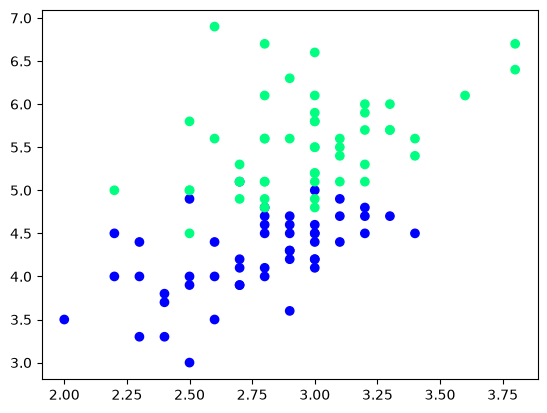

In [11]:
plt.scatter(df['SepalWidthCm'],df['PetalLengthCm'],c=df['Species'],cmap='winter')

In [12]:
df_train = df.iloc[:60,:].sample(10)
df_train

,SepalWidthCm,PetalLengthCm,Species
104,3.0,5.8,2
66,3.0,4.5,1
56,3.3,4.7,1
85,3.4,4.5,1
55,2.8,4.5,1
88,3.0,4.1,1
101,2.7,5.1,2
70,3.2,4.8,1
84,3.0,4.5,1
96,2.9,4.2,1


In [21]:
# Taking only 10 rows for training
df = df.sample(100,random_state=42)
df_train = df.iloc[:60,:].sample(10)
df_val = df.iloc[60:80,:].sample(5)
df_test = df.iloc[80:,:].sample(5)

In [22]:
df_train

,SepalWidthCm,PetalLengthCm,Species
80,2.4,3.8,1
79,2.6,3.5,1
105,3.0,6.6,2
129,3.0,5.8,2
83,2.7,5.1,1
143,3.2,5.9,2
96,2.9,4.2,1
50,3.2,4.7,1
94,2.7,4.2,1
67,2.7,4.1,1


In [23]:
df_val

,SepalWidthCm,PetalLengthCm,Species
53,2.3,4.0,1
138,3.0,4.8,2
56,3.3,4.7,1
144,3.3,5.7,2
103,2.9,5.6,2


In [24]:
df_test

,SepalWidthCm,PetalLengthCm,Species
92,2.6,4.0,1
132,2.8,5.6,2
76,2.8,4.8,1
109,3.6,6.1,2
70,3.2,4.8,1


In [25]:
X_test = df_val.iloc[:,0:2].values
y_test = df_val.iloc[:,-1].values
y_test

array([1, 2, 1, 2, 2])

## CASE 1 - Bagging

In [26]:
# Data for Tree 1
df_bag = df_train.sample(8,replace=True)

X = df_bag.iloc[:,0:2]
y = df_bag.iloc[:,-1]

df_bag

,SepalWidthCm,PetalLengthCm,Species
83,2.7,5.1,1
143,3.2,5.9,2
129,3.0,5.8,2
105,3.0,6.6,2
129,3.0,5.8,2
79,2.6,3.5,1
67,2.7,4.1,1
67,2.7,4.1,1


In [26]:
pip install mlxtend

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [27]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from sklearn.metrics import accuracy_score
from mlxtend.plotting import plot_decision_regions

In [28]:
dt_bag1 = DecisionTreeClassifier()

In [29]:
def evaluate(clf,X,y):
    clf.fit(X,y)
    plot_tree(clf)
    plt.show()
    plot_decision_regions(X.values, y.values, clf=clf, legend=2)
    y_pred = clf.predict(X_test)
    print(accuracy_score(y_test,y_pred))

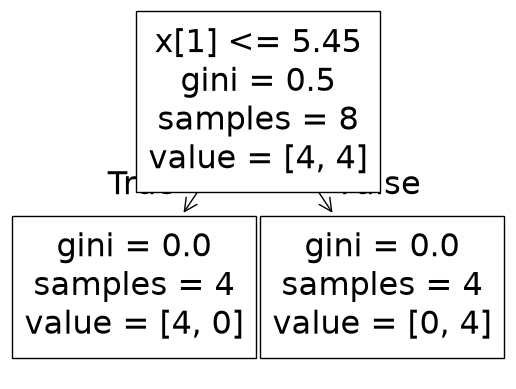

C:\Users\HP\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
C:\Users\HP\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


0.8


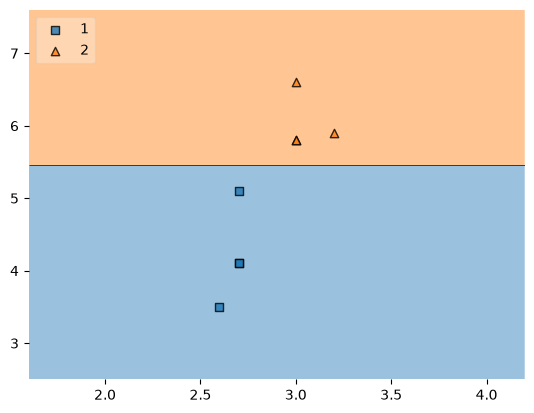

In [30]:
evaluate(dt_bag1,X,y)

In [31]:
# Data for Tree 1
df_bag = df_train.sample(8,replace=True)

# Fetch X and y
X = df_bag.iloc[:,0:2]
y = df_bag.iloc[:,-1]

# print df_bag
df_bag

,SepalWidthCm,PetalLengthCm,Species
143,3.2,5.9,2
129,3.0,5.8,2
94,2.7,4.2,1
129,3.0,5.8,2
79,2.6,3.5,1
79,2.6,3.5,1
94,2.7,4.2,1
96,2.9,4.2,1


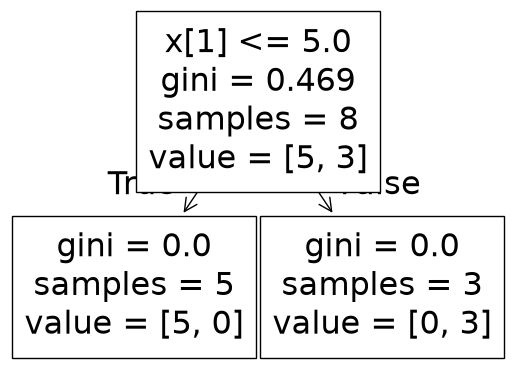

C:\Users\HP\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
C:\Users\HP\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


0.8


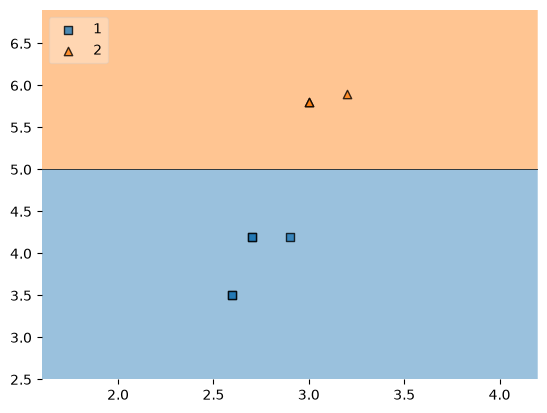

In [32]:
dt_bag2 = DecisionTreeClassifier()
evaluate(dt_bag2,X,y)

In [36]:
# Data for Tree 1
df_bag = df_train.sample(8,replace=True)

# Fetch X and y
X = df_bag.iloc[:,0:2]
y = df_bag.iloc[:,-1]

# print df_bag
df_bag

,SepalWidthCm,PetalLengthCm,Species
94,2.7,4.2,1
83,2.7,5.1,1
96,2.9,4.2,1
143,3.2,5.9,2
50,3.2,4.7,1
94,2.7,4.2,1
94,2.7,4.2,1
79,2.6,3.5,1


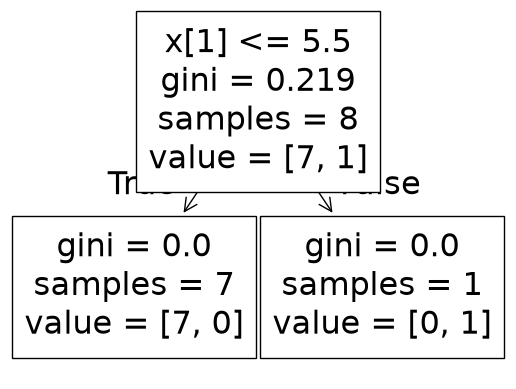

C:\Users\HP\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
C:\Users\HP\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


0.8


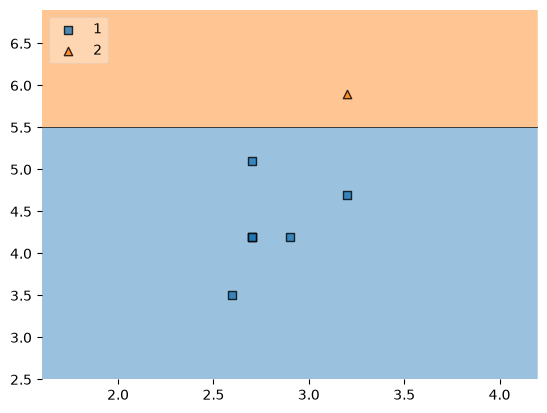

In [37]:
dt_bag3 = DecisionTreeClassifier()
evaluate(dt_bag3,X,y)

## Predict

In [38]:
df_test

,SepalWidthCm,PetalLengthCm,Species
92,2.6,4.0,1
132,2.8,5.6,2
76,2.8,4.8,1
109,3.6,6.1,2
70,3.2,4.8,1


In [41]:
print("Predictor 1",dt_bag1.predict(np.array([2.8,5.6]).reshape(1,2)))
print("Predictor 2",dt_bag2.predict(np.array([2.8,5.6]).reshape(1,2)))
print("Predictor 3",dt_bag3.predict(np.array([2.8,5.6]).reshape(1,2)))

Predictor 1 [2]
Predictor 2 [2]
Predictor 3 [2]


C:\Users\HP\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
C:\Users\HP\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
C:\Users\HP\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


## Types of Bagging

## Pasting

In [42]:
# Row sampling without replacement
df_train

,SepalWidthCm,PetalLengthCm,Species
80,2.4,3.8,1
79,2.6,3.5,1
105,3.0,6.6,2
129,3.0,5.8,2
83,2.7,5.1,1
143,3.2,5.9,2
96,2.9,4.2,1
50,3.2,4.7,1
94,2.7,4.2,1
67,2.7,4.1,1


In [43]:
df_train.sample(8)

,SepalWidthCm,PetalLengthCm,Species
83,2.7,5.1,1
50,3.2,4.7,1
96,2.9,4.2,1
80,2.4,3.8,1
94,2.7,4.2,1
67,2.7,4.1,1
105,3.0,6.6,2
129,3.0,5.8,2


## Random Subspaces

In [45]:
df1 = pd.read_csv('Iris.csv')
df1 = df1.sample(10)

In [46]:
df1

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
41,42,4.5,2.3,1.3,0.3,Iris-setosa
138,139,6.0,3.0,4.8,1.8,Iris-virginica
136,137,6.3,3.4,5.6,2.4,Iris-virginica
129,130,7.2,3.0,5.8,1.6,Iris-virginica
118,119,7.7,2.6,6.9,2.3,Iris-virginica
131,132,7.9,3.8,6.4,2.0,Iris-virginica
146,147,6.3,2.5,5.0,1.9,Iris-virginica
62,63,6.0,2.2,4.0,1.0,Iris-versicolor
43,44,5.0,3.5,1.6,0.6,Iris-setosa
115,116,6.4,3.2,5.3,2.3,Iris-virginica


In [48]:
df1.sample(2,replace=True,axis=1)

,Species,PetalWidthCm
41,Iris-setosa,0.3
138,Iris-virginica,1.8
136,Iris-virginica,2.4
129,Iris-virginica,1.6
118,Iris-virginica,2.3
131,Iris-virginica,2.0
146,Iris-virginica,1.9
62,Iris-versicolor,1.0
43,Iris-setosa,0.6
115,Iris-virginica,2.3


## Random Patches

In [45]:
df1

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
62,63,6.0,2.2,4.0,1.0,Iris-versicolor
12,13,4.8,3.0,1.4,0.1,Iris-setosa
140,141,6.7,3.1,5.6,2.4,Iris-virginica
59,60,5.2,2.7,3.9,1.4,Iris-versicolor
25,26,5.0,3.0,1.6,0.2,Iris-setosa
9,10,4.9,3.1,1.5,0.1,Iris-setosa
92,93,5.8,2.6,4.0,1.2,Iris-versicolor
48,49,5.3,3.7,1.5,0.2,Iris-setosa
10,11,5.4,3.7,1.5,0.2,Iris-setosa
61,62,5.9,3.0,4.2,1.5,Iris-versicolor


In [50]:
df1.sample(8,replace=True).sample(2,replace=True,axis=1)

,Species,SepalLengthCm
138,Iris-virginica,6.0
131,Iris-virginica,7.9
41,Iris-setosa,4.5
118,Iris-virginica,7.7
118,Iris-virginica,7.7
43,Iris-setosa,5.0
146,Iris-virginica,6.3
43,Iris-setosa,5.0
